# Import library & konfigurasi

In [4]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, precision_recall_curve,
                             confusion_matrix, classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
PRIMARY, SECONDARY, NEUTRAL = "#4C72B0", "#55A868", "#7F7F7F"
sns.set_palette([PRIMARY, SECONDARY])
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})
print("Library ready. Seed:", RANDOM_STATE)

Library ready. Seed: 42


# Import data

In [5]:
raw_df = pd.read_csv("creditcard.csv")
print(f"Dataset: {raw_df} | row: {len(raw_df):,} | column: {raw_df.shape[1]}")
raw_df.head(3)

Dataset:             Time         V1         V2        V3        V4        V5  \
0            0.0  -1.359807  -0.072781  2.536347  1.378155 -0.338321   
1            0.0   1.191857   0.266151  0.166480  0.448154  0.060018   
2            1.0  -1.358354  -1.340163  1.773209  0.379780 -0.503198   
3            1.0  -0.966272  -0.185226  1.792993 -0.863291 -0.010309   
4            2.0  -1.158233   0.877737  1.548718  0.403034 -0.407193   
...          ...        ...        ...       ...       ...       ...   
284802  172786.0 -11.881118  10.071785 -9.834783 -2.066656 -5.364473   
284803  172787.0  -0.732789  -0.055080  2.035030 -0.738589  0.868229   
284804  172788.0   1.919565  -0.301254 -3.249640 -0.557828  2.630515   
284805  172788.0  -0.240440   0.530483  0.702510  0.689799 -0.377961   
284806  172792.0  -0.533413  -0.189733  0.703337 -0.506271 -0.012546   

              V6        V7        V8        V9  ...       V21       V22  \
0       0.462388  0.239599  0.098698  0.363787  ...

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


# Data cleaning

In [8]:
expected_columns = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]
missing_cols = sorted(set(expected_columns) - set(raw_df.columns))
if missing_cols: raise ValueError(f"Miss Column: {missing_cols}")

for col in expected_columns:
    raw_df[col] = pd.to_numeric(raw_df[col], errors="raise")

quality = pd.DataFrame({
    "Check": ["Row", "Column", "Missing feature", "Missing label",
              "Duplicate exact", "Fraud case", "Fraud prevalence"],
    "Result": [f"{len(raw_df):,}", raw_df.shape[1],
               f"{raw_df.drop(columns='Class').isna().sum().sum():,}",
               int(raw_df['Class'].isna().sum()), f"{raw_df.duplicated().sum():,}",
               f"{int(raw_df['Class'].sum()):,}", f"{raw_df['Class'].mean():.3%}"]})
display(quality)
# Remove exact duplicates so that identical rows do not leak across splits
df = raw_df[expected_columns].drop_duplicates().reset_index(drop=True)
print(f"After dedup: {len(df):,} row | fraud: {int(df['Class'].sum()):,} ({df['Class'].mean():.3%})")

,Check,Result
0,Row,"284,807"
1,Column,31
2,Missing feature,0
3,Missing label,0
4,Duplicate exact,"1,081"
5,Fraud case,492
6,Fraud prevalence,0.173%


After dedup: 283,726 row | fraud: 473 (0.167%)


# Split stratified 60/20/20
(before EDA & modeling)

In [9]:
X = df.drop(columns="Class"); y = df["Class"].astype(int)

X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.25, stratify=y_tv, random_state=RANDOM_STATE)

display(pd.DataFrame({
    "Transaction": [len(y_train), len(y_val), len(y_test)],
    "Fraud": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "% Fraud": [f"{r:.3%}" for r in (y_train.mean(), y_val.mean(), y_test.mean())]},
    index=["Train (60%)", "Validation (20%)", "Test (20%)"]))

,Transaction,Fraud,% Fraud
Train (60%),170235,284,0.167%
Validation (20%),56745,94,0.166%
Test (20%),56746,95,0.167%


# EDA

## EDA 1: imbalance & base rate

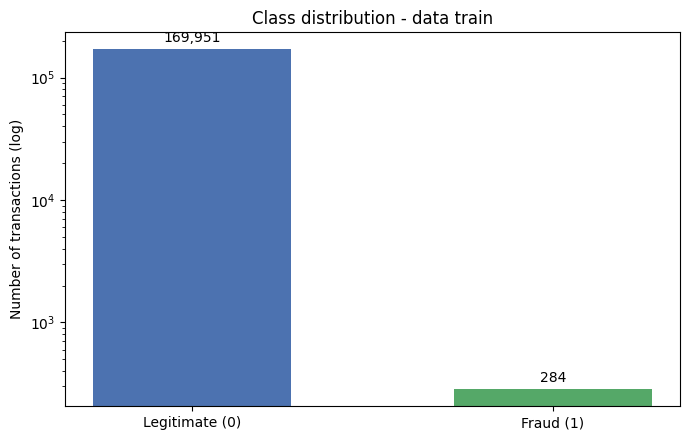

'Always legitimate' baseline: 99.833% accuracy, but 0% fraud recall
=> Accuracy is not significant in imbalance data; focus on Precision, Recall, and AP (AUPRC).


In [13]:
train_df = X_train.copy(); train_df["Class"] = y_train
counts = y_train.value_counts().reindex([0, 1], fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(["Legitimate (0)", "Fraud (1)"], counts.values, color=[PRIMARY, SECONDARY], width=0.55)
ax.set_yscale("log"); ax.set_ylabel("Number of transactions (log)")
ax.set_title("Class distribution - data train")
for b, c in zip(bars, counts.values):
    ax.annotate(f"{c:,}", (b.get_x()+b.get_width()/2, c), xytext=(0, 5), textcoords="offset points", ha="center")
plt.tight_layout(); plt.show()

print(f"'Always legitimate' baseline: {(y_train==0).mean():.3%} accuracy, but 0% fraud recall")
print("=> Accuracy is not significant in imbalance data; focus on Precision, Recall, and AP (AUPRC).")

## EDA 2: Amount & Time Distribution

,Statistic,Amount
0,Mean,88.161
1,Median,22.040
2,IQR,71.895
3,p95,363.216
4,p99,"1,011.155"
5,Skewness,15.196


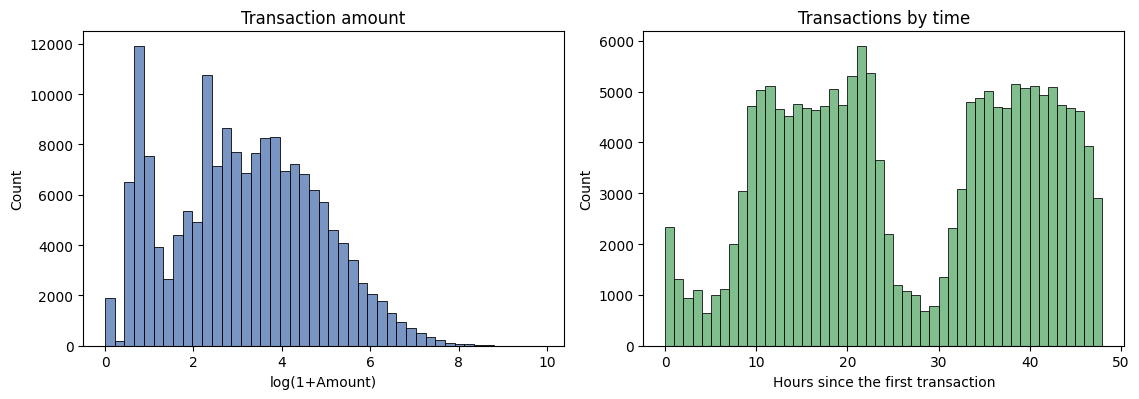

In [14]:
st = X_train["Amount"].describe(percentiles=[.25, .5, .75, .95, .99])
display(pd.DataFrame({"Statistic": ["Mean", "Median", "IQR", "p95", "p99", "Skewness"],
                      "Amount": [st["mean"], st["50%"], st["75%"]-st["25%"], st["95%"], st["99%"],
                                 X_train["Amount"].skew()]}).style.format({"Amount": "{:,.3f}"}))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1))
sns.histplot(np.log1p(X_train["Amount"].clip(lower=0)), bins=45, color=PRIMARY, ax=axes[0])
axes[0].set(title="Transaction amount", xlabel="log(1+Amount)", ylabel="Count")
sns.histplot(X_train["Time"]/3600, bins=48, color=SECONDARY, ax=axes[1])
axes[1].set(title="Transactions by time", xlabel="Hours since the first transaction", ylabel="Count")
plt.tight_layout(); plt.show()

## EDA 3: correlation of features with the Class

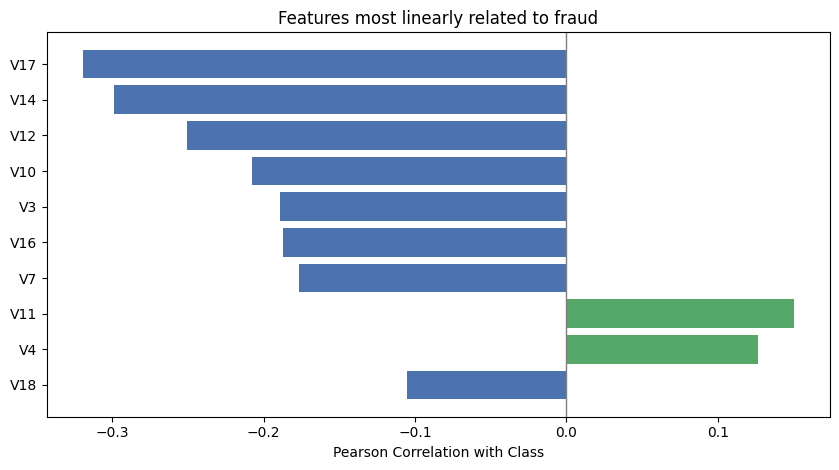

,Pearson r
V17,-0.320
V14,-0.299
V12,-0.251
V10,-0.208
V3,-0.189
V16,-0.187
V7,-0.177
V11,0.151
V4,0.127
V18,-0.105


In [15]:
correlations = train_df.corr(numeric_only=True)["Class"].drop("Class")
top_corr = correlations.reindex(correlations.abs().nlargest(10).index)
ordered = top_corr.iloc[::-1]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(ordered.index, ordered.values, color=[SECONDARY if v >= 0 else PRIMARY for v in ordered])
ax.axvline(0, color=NEUTRAL, lw=1)
ax.set(xlabel="Pearson Correlation with Class", title="Features most linearly related to fraud")
plt.tight_layout(); plt.show()
display(top_corr.round(3).to_frame("Pearson r"))

## EDA 4: outliers as signals, not noise

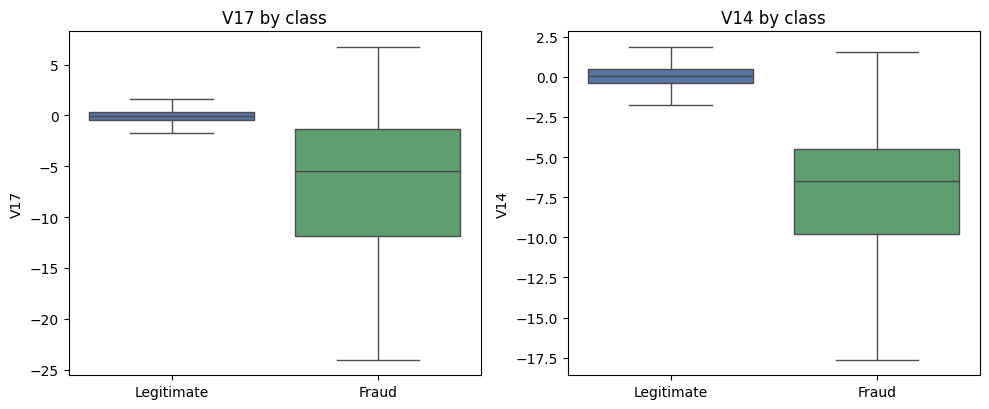

Fraud often lies outside the boundaries of what is considered legitimate; therefore, removing 'outliers' actually means discarding the very signals you need.


In [18]:
normal = train_df[train_df["Class"] == 0]; fraud = train_df[train_df["Class"] == 1]
box_features = list(top_corr.index[:2])

rows = []
for f in box_features:
    q1, q3 = normal[f].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    for label, sub in [("Legitimate", normal), ("Fraud", fraud)]:
        rows.append({"Feature": f, "Class": label,
                     "Outside the legitimate fence": ((sub[f] < lo) | (sub[f] > hi)).mean()})
display(pd.DataFrame(rows).set_index(["Feature", "Class"]).style.format("{:.1%}"))

sample = pd.concat([normal.sample(n=min(2000, len(normal)), random_state=RANDOM_STATE), fraud])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, f in zip(axes, box_features):
    sns.boxplot(data=sample, x="Class", y=f, hue="Class", palette={0: PRIMARY, 1: SECONDARY},
                dodge=False, showfliers=False, ax=ax)
    if ax.get_legend(): ax.get_legend().remove()
    ax.set_xticks([0, 1], ["Legitimate", "Fraud"]); ax.set(title=f"{f} by class", xlabel="")
plt.tight_layout(); plt.show()
print("Fraud often lies outside the boundaries of what is considered legitimate; therefore, removing 'outliers' actually means discarding the very signals you need.")

# Define 4 comparative models

In [19]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", DecisionTreeClassifier(max_depth=8, min_samples_leaf=5,
                                       class_weight="balanced", random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", RandomForestClassifier(n_estimators=150, min_samples_leaf=2,
                                       class_weight="balanced_subsample",
                                       random_state=RANDOM_STATE, n_jobs=-1))]),
    "Gradient Boosting (HistGB)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                               class_weight="balanced", random_state=RANDOM_STATE))]),
}
print("4 model:", ", ".join(models))

4 model: Logistic Regression, Decision Tree, Random Forest, Gradient Boosting (HistGB)


# Train all models & compare in validation

In [20]:
val_probs, rows = {}, []
for name, pipe in models.items():
    print(f"Training {name} ...")
    pipe.fit(X_train, y_train)
    prob = pipe.predict_proba(X_val)[:, 1]
    pred = (prob >= 0.5).astype(int)
    val_probs[name] = prob
    rows.append({"Model": name,
                 "AP (AUPRC)": average_precision_score(y_val, prob),
                 "ROC-AUC": roc_auc_score(y_val, prob),
                 "Precision@.5": precision_score(y_val, pred, zero_division=0),
                 "Recall@.5": recall_score(y_val, pred, zero_division=0),
                 "F1@.5": f1_score(y_val, pred, zero_division=0)})
val_table = pd.DataFrame(rows).set_index("Model").round(4)
display(val_table)

Training Logistic Regression ...
Training Decision Tree ...
Training Random Forest ...
Training Gradient Boosting (HistGB) ...


,AP (AUPRC),ROC-AUC,Precision@.5,Recall@.5,F1@.5
Model,,,,,
Logistic Regression,0.7876,0.9790,0.0538,0.9043,0.1016
Decision Tree,0.4766,0.9136,0.1472,0.8298,0.2500
Random Forest,0.8742,0.9554,0.9186,0.8404,0.8778
Gradient Boosting (HistGB),0.7655,0.9426,0.3850,0.8723,0.5342


# Number of true alerts in validation (threshold 0.5)

In [21]:
rows = []
for name, prob in val_probs.items():
    tn, fp, fn, tp = confusion_matrix(y_val, (prob >= 0.5).astype(int), labels=[0, 1]).ravel()
    rows.append({"Model": name, "Fraud caught (TP)": int(tp), "Fraud missed (FN)": int(fn),
                 "False alarm (FP)": int(fp),
                 "Alert per fraud": round((tp+fp)/tp, 2) if tp else np.nan})
display(pd.DataFrame(rows).set_index("Model"))

,Fraud caught (TP),Fraud missed (FN),False alarm (FP),Alert per fraud
Model,,,,
Logistic Regression,85,9,1495,18.59
Decision Tree,78,16,452,6.79
Random Forest,79,15,7,1.09
Gradient Boosting (HistGB),82,12,131,2.60


# Precision–Recall curve & selecting the best model

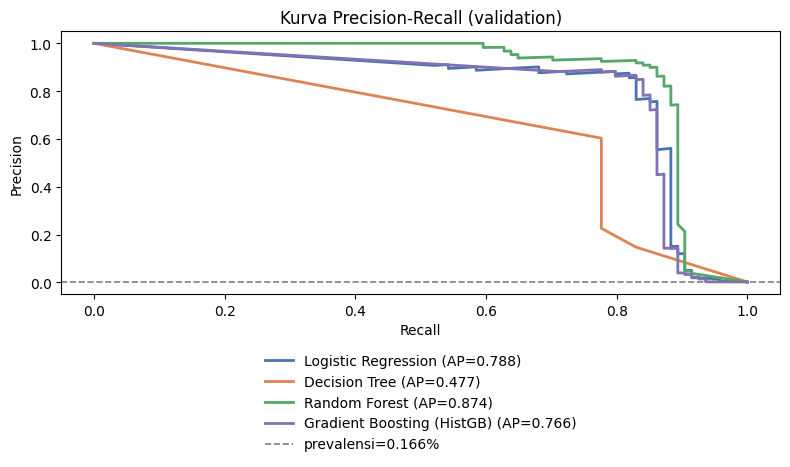

Best model based on AP on validation: Random Forest


In [22]:
palette = {"Logistic Regression": PRIMARY, "Decision Tree": "#DD8452",
           "Random Forest": SECONDARY, "Gradient Boosting (HistGB)": "#8172B3"}
fig, ax = plt.subplots(figsize=(8, 5))
for name, prob in val_probs.items():
    p, r, _ = precision_recall_curve(y_val, prob)
    ax.plot(r, p, color=palette[name], lw=2, label=f"{name} (AP={average_precision_score(y_val, prob):.3f})")
ax.axhline(y_val.mean(), color=NEUTRAL, ls="--", lw=1.2, label=f"prevalensi={y_val.mean():.3%}")
ax.set(xlabel="Recall", ylabel="Precision", title="Kurva Precision-Recall (validation)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout(); plt.show()

best_model = val_table["AP (AUPRC)"].idxmax()
print(f"Best model based on AP on validation: {best_model}")

# Threshold alert for the best model (validation only)

In [23]:
TARGET_RECALL = 0.80
p, r, thr = precision_recall_curve(y_val, val_probs[best_model])
opts = pd.DataFrame({"thr": thr, "precision": p[:-1], "recall": r[:-1]})
valid = opts[opts.recall >= TARGET_RECALL]
if valid.empty: raise RuntimeError("No threshold meets the recall target..")
chosen = valid[np.isclose(valid.precision, valid.precision.max())].sort_values("thr").iloc[-1]
threshold = float(chosen.thr)
display(pd.DataFrame({"Value": [TARGET_RECALL, threshold, chosen.precision, chosen.recall]},
                     index=["Target recall", "Threshold terpilih",
                            "Precision@thr", "Recall@thr"]).round(4))

,Value
Target recall,0.8000
Threshold terpilih,0.5463
Precision@thr,0.9286
Recall@thr,0.8298


# Final evaluation on the test set (accessed only once)

In [25]:
rows = []
for name, pipe in models.items():
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"Model": name, "AP": average_precision_score(y_test, prob),
                 "ROC-AUC": roc_auc_score(y_test, prob),
                 "Precision": precision_score(y_test, pred, zero_division=0),
                 "Recall": recall_score(y_test, pred, zero_division=0),
                 "F1": f1_score(y_test, pred, zero_division=0), "FP": int(fp), "FN": int(fn)})

prob_best = models[best_model].predict_proba(X_test)[:, 1]
pred_best = (prob_best >= threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred_best, labels=[0, 1]).ravel()
rows.append({"Model": f"{best_model} (selected thread)", "AP": average_precision_score(y_test, prob_best),
             "ROC-AUC": roc_auc_score(y_test, prob_best),
             "Precision": precision_score(y_test, pred_best, zero_division=0),
             "Recall": recall_score(y_test, pred_best, zero_division=0),
             "F1": f1_score(y_test, pred_best, zero_division=0), "FP": int(fp), "FN": int(fn)})
test_table = pd.DataFrame(rows).set_index("Model").round(4)
display(test_table.sort_values("AP", ascending=False))

,AP,ROC-AUC,Precision,Recall,F1,FP,FN
Model,,,,,,,
Random Forest,0.8149,0.9338,0.9714,0.7158,0.8242,2,27
Random Forest (selected thread),0.8149,0.9338,0.9714,0.7158,0.8242,2,27
Gradient Boosting (HistGB),0.7143,0.9427,0.3949,0.8105,0.5310,118,18
Logistic Regression,0.6865,0.9646,0.0508,0.8737,0.0961,1550,12
Decision Tree,0.5626,0.8988,0.1545,0.8000,0.2589,416,19


# Confusion matrix, classification report, interval Wilson

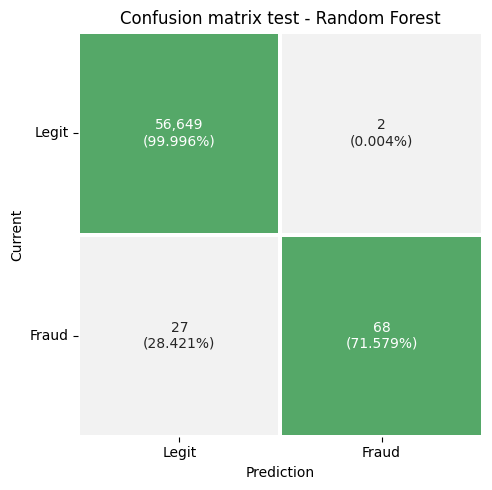

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.97      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746

Recall test: 71.579% | Wilson 95% CI: 61.809% s/d 79.672%


In [27]:
counts = confusion_matrix(y_test, pred_best, labels=[0, 1])
shares = counts / counts.sum(axis=1, keepdims=True)
annot = np.array([[f"{c:,}\n({s:.3%})" for c, s in zip(row, sh)] for row, sh in zip(counts, shares)])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(shares, annot=annot, fmt="", cmap=["#F2F2F2", SECONDARY], vmin=0, vmax=1,
            square=True, cbar=False, linewidths=1.5, linecolor="white", ax=ax)
ax.set(xlabel="Prediction", ylabel="Current", title=f"Confusion matrix test - {best_model}")
ax.set_xticklabels(["Legit", "Fraud"], rotation=0); ax.set_yticklabels(["Legit", "Fraud"], rotation=0)
plt.tight_layout(); plt.show()

print(classification_report(y_test, pred_best, target_names=["Legitimate", "Fraud"], zero_division=0))

n = tp + fn; p_hat = tp / n; z, d = 1.96, 1 + 1.96**2/n
center = (p_hat + z*z/(2*n)) / d
half = (z/d) * np.sqrt(p_hat*(1-p_hat)/n + z*z/(4*n*n))
print(f"Recall test: {p_hat:.3%} | Wilson 95% CI: {center-half:.3%} s/d {center+half:.3%}")

# Interpretabilitas: fitur terpenting model terbaik

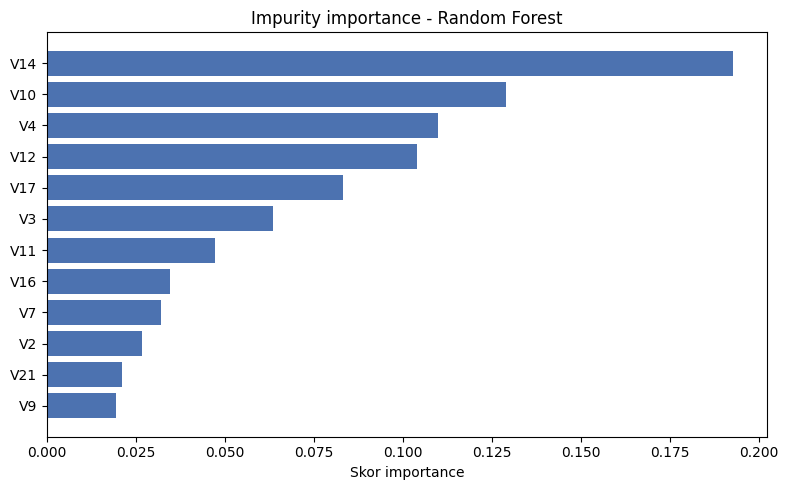

Importance is not a causal relationship, and anonymized PCA features have no direct business meaning.


In [28]:
clf = models[best_model].named_steps["clf"]
if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=X_train.columns).nlargest(12).sort_values()
    title = f"Impurity importance - {best_model}"
elif hasattr(clf, "coef_"):
    imp = pd.Series(clf.coef_.ravel(), index=X_train.columns).abs().nlargest(12).sort_values()
    title = f"|Koefisien| - {best_model}"
else:  # HistGB does not have feature_importances_ -> permutation importance
    res = permutation_importance(models[best_model], X_val, y_val, n_repeats=5,
                                 random_state=RANDOM_STATE, scoring="average_precision")
    imp = pd.Series(res.importances_mean, index=X_train.columns).nlargest(12).sort_values()
    title = f"Permutation importance (AP) - {best_model}"

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(imp.index, imp.values, color=PRIMARY)
ax.set(xlabel="Skor importance", title=title)
plt.tight_layout(); plt.show()
print("Importance is not a causal relationship, and anonymized PCA features have no direct business meaning.")

# Conclusion

In [29]:
print("=== Model rank in TEST based on AP (AUPRC) ===")
display(test_table.sort_values("AP", ascending=False))
print(f"Best model: {best_model} (AP validation {val_table.loc[best_model, 'AP (AUPRC)']:.4f})")
print(f"At selected threshold {threshold:.4f}: recall test {test_table.iloc[-1]['Recall']:.1%}, "
      f"precision {test_table.iloc[-1]['Precision']:.1%}, false alarm {int(test_table.iloc[-1]['FP'])}.")
print("Note: with fraud <1% in data, compare AP/AUPRC late model and number of alerts, not accuracy.")

=== Model rank in TEST based on AP (AUPRC) ===


,AP,ROC-AUC,Precision,Recall,F1,FP,FN
Model,,,,,,,
Random Forest,0.8149,0.9338,0.9714,0.7158,0.8242,2,27
Random Forest (selected thread),0.8149,0.9338,0.9714,0.7158,0.8242,2,27
Gradient Boosting (HistGB),0.7143,0.9427,0.3949,0.8105,0.5310,118,18
Logistic Regression,0.6865,0.9646,0.0508,0.8737,0.0961,1550,12
Decision Tree,0.5626,0.8988,0.1545,0.8000,0.2589,416,19


Best model: Random Forest (AP validation 0.8742)
At selected threshold 0.5463: recall test 71.6%, precision 97.1%, false alarm 2.
Note: with fraud <1% in data, compare AP/AUPRC late model and number of alerts, not accuracy.


# Export model

In [30]:
import joblib
best_pipeline = models[best_model]
model_filename = "best_credit_card_fraud_rf.joblib"
joblib.dump(best_pipeline, model_filename)

print(f"Best model ({best_model}) successfully exported to: {model_filename}")

Best model (Random Forest) successfully exported to: best_credit_card_fraud_rf.joblib
